## 1. Imports and shared code

In [1]:
import sys
import time
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.embedding import average_mutual_information, first_local_minimum, false_nearest_fraction
from recplay.windowed import (rqa_frame, rrc_frame, window_surrogates, euclidean_distance,
                              exp_euclidean_distance, beta_distance)

## 2. Data

In [2]:
# Load FRED monthly series
DATA_DIR = Path("../../data/raw/fred")  # relative to notebooks/02_macro/, where this notebook lives

def load_csv(name: str) -> pd.Series:
    df = pd.read_csv(DATA_DIR / f"{name}.csv", parse_dates=["observation_date"], index_col="observation_date")
    return df[name].astype(float)

cpi = load_csv("CPIAUCSL")
unrate = load_csv("UNRATE")
fedfunds = load_csv("FEDFUNDS")

for s in (cpi, unrate, fedfunds):
    print(f"{s.name:9s} {s.index.min().date()} to {s.index.max().date()}  n={len(s)}  missing={s.isna().sum()}")

CPIAUCSL  1947-01-01 to 2026-09-01  n=957  missing=1
UNRATE    1948-01-01 to 2026-09-01  n=945  missing=1
FEDFUNDS  1954-07-01 to 2026-09-01  n=867  missing=0


In [3]:
# Impute October 2025 as Bureau of labor stats did not collect CPI or household-survey data during the shutdown

cpi_m, unrate_m, fedfunds_m = (s.asfreq("MS") for s in (cpi, unrate, fedfunds))

cpi_imputed = cpi_m.isna()
unrate_imputed = unrate_m.isna()

print("Imputing CPI at:", list(cpi_m.index[cpi_imputed].date))
print("Imputing UNRATE at:", list(unrate_m.index[unrate_imputed].date))
assert not fedfunds_m.isna().any()

cpi_clean = np.exp(np.log(cpi_m).interpolate(method="linear", limit_area="inside"))  # geometric for a price level
unrate_clean = unrate_m.interpolate(method="linear", limit_area="inside")
fedfunds_clean = fedfunds_m

print(pd.DataFrame({"CPIAUCSL": cpi_clean, "UNRATE": unrate_clean}).loc["2025-09":"2025-11"])

Imputing CPI at: [datetime.date(2025, 10, 1)]
Imputing UNRATE at: [datetime.date(2025, 10, 1)]
                    CPIAUCSL  UNRATE
observation_date                    
2025-09-01        324.245000    4.40
2025-10-01        324.653742    4.45
2025-11-01        325.063000    4.50


In [4]:
# CPI level turned to YoY inflation, on the full CPI history (1947-), thus no lost months at the 1954 start
# YoY inflation instead of MoM inflation, avoiding overly noisy periods 
inflation = (100 * (np.log(cpi_clean) - np.log(cpi_clean.shift(12)))).rename("INFLATION")

# A YoY value is imputed if either of its two CPI inputs was imputed
inflation_imputed = cpi_imputed | cpi_imputed.shift(12, fill_value=False)

inflation = inflation.dropna()
inflation_imputed = inflation_imputed.loc[inflation.index]
print(f"INFLATION {inflation.index.min().date()} to {inflation.index.max().date()}  n={len(inflation)}")

INFLATION 1948-01-01 to 2026-09-01  n=945


In [5]:
# Common window, checks
macro = pd.concat([inflation, unrate_clean, fedfunds_clean], axis=1, join="inner")
macro["IMPUTED"] = (inflation_imputed | unrate_imputed).loc[macro.index]

assert macro.index.is_monotonic_increasing and macro.index.is_unique
assert len(macro.asfreq("MS")) == len(macro), "gap in monthly index"
assert not macro.isna().any().any(), "NaN left after cleaning"

print(f"{macro.index.min().date()} to {macro.index.max().date()}  n={len(macro)}")
print("Imputed rows:", list(macro.index[macro["IMPUTED"]].date))
macro.head()

1954-07-01 to 2026-09-01  n=867
Imputed rows: [datetime.date(2025, 10, 1)]


,INFLATION,UNRATE,FEDFUNDS,IMPUTED
observation_date,,,,
1954-07-01,0.260951,5.8,0.80,False
1954-08-01,0.000000,6.0,1.22,False
1954-09-01,-0.297952,6.1,1.07,False
1954-10-01,-0.857095,5.7,0.85,False
1954-11-01,-0.261048,5.3,0.83,False


In [6]:
# Monthly inflation on the full CPI history, so its lags are complete from 1954-07; YoY is exactly its 12-month sum
pi = (100 * np.log(cpi_clean).diff()).rename("PI")
macro["PI"] = pi.loc[macro.index]
assert np.allclose(pi.rolling(12).sum().loc[macro.index], macro.INFLATION)

## 3. Targets and evaluation calendar

In [7]:
HORIZONS = [1, 3, 6, 12]
SCREEN_YEARS = (1975, 1999)
FINAL_YEARS = (2000, 2026)
yoy = macro.INFLATION

# Row t is 1 if YoY h months later is strictly higher than at t
targets = {h: (yoy.shift(-h) > yoy).astype(int)[yoy.shift(-h).notna()] for h in HORIZONS}
label_imputed = {h: (macro.IMPUTED | macro.IMPUTED.shift(-h, fill_value=False)).loc[targets[h].index] for h in HORIZONS}


def blocks(h, first_year, last_year):
    """The model for year Y is fitted at the start of Y, on rows whose h-month label is known by then."""
    idx = targets[h].index
    for year in range(first_year, last_year + 1):
        start = pd.Timestamp(year, 1, 1)
        train = idx.shift(h, freq="MS") <= start
        test = idx.year == year
        if not test.any():
            continue
        assert idx[train].max() + pd.DateOffset(months=h) <= start <= idx[test].min()
        yield train, test


def scored_rows(h, first_year, last_year):
    test = np.zeros(len(targets[h]), bool)
    for _, t in blocks(h, first_year, last_year):
        test |= t
    return test & ~label_imputed[h].to_numpy()


def make_classifier():
    return LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, num_leaves=7, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, n_jobs=1, verbose=-1)


def evaluate(X, h, first_year, last_year):
    y = targets[h]
    has = y.index.isin(X.index)
    X = X.reindex(y.index)
    pred = pd.Series(np.nan, index=y.index)
    for train, test in blocks(h, first_year, last_year):
        train &= has
        assert has[test].all()
        model = make_classifier().fit(X[train], y[train])
        pred[test] = model.predict_proba(X[test])[:, 1]
    rows = scored_rows(h, first_year, last_year)
    p, t = pred[rows], y[rows]
    return {"auc": roc_auc_score(t, p), "acc": accuracy_score(t, p >= 0.5), "n_test": int(rows.sum())}, p


def auc_gain(p_new, p_base, labels, n=2000):
    """AUC(p_new) - AUC(p_base) on the same months, with a 95% interval from resampling whole calendar years."""
    t = labels[p_new.index]
    years = p_new.index.year
    groups = [np.flatnonzero(years == yr) for yr in np.unique(years)]
    rng = np.random.default_rng(0)
    diffs = []
    for _ in range(n):
        i = np.concatenate([groups[g] for g in rng.integers(0, len(groups), len(groups))])
        diffs.append(roc_auc_score(t.iloc[i], p_new.iloc[i]) - roc_auc_score(t.iloc[i], p_base.iloc[i]))
    return roc_auc_score(t, p_new) - roc_auc_score(t, p_base), *np.quantile(diffs, [0.025, 0.975])


print(pd.DataFrame({h: {"screening rows": scored_rows(h, *SCREEN_YEARS).sum(),
                        "final rows": scored_rows(h, *FINAL_YEARS).sum()} for h in HORIZONS}))

                 1    3    6    12
screening rows  300  300  300  300
final rows      318  316  313  308


## 4. Lag and base-effect features

In [8]:
def lagged_values(data=macro):
    dpi = data.INFLATION.diff()
    return pd.concat({f"dpi_lag{k}": dpi.shift(k) for k in range(12)}, axis=1).join(data[["INFLATION", "UNRATE", "FEDFUNDS"]])


def base_effect(h, pi=pi):
    """π_{t-11} + ... + π_{t-12+h}: the monthly inflation that leaves the YoY sum over the next h months."""
    return pi.rolling(h).sum().shift(12 - h)


def lags_base(h, data=macro, pi=pi):
    pi_lags = pd.concat({f"pi_lag{k}": pi.shift(k) for k in range(13)}, axis=1)
    return lagged_values(data).join(pi_lags).join(base_effect(h, pi).rename("base_effect"))


# YoY(t+h) - YoY(t) = (π_{t+1} + ... + π_{t+h}) - base effect, so only the first sum is unknown at t
for h in HORIZONS:
    gap = (yoy.shift(-h) - yoy) - (pi.rolling(h).sum().shift(-h) - base_effect(h)).loc[macro.index]
    assert gap.abs().max() < 1e-9

lag_base_features = {h: lags_base(h) for h in HORIZONS}

## 5. Embedding chosen from the data

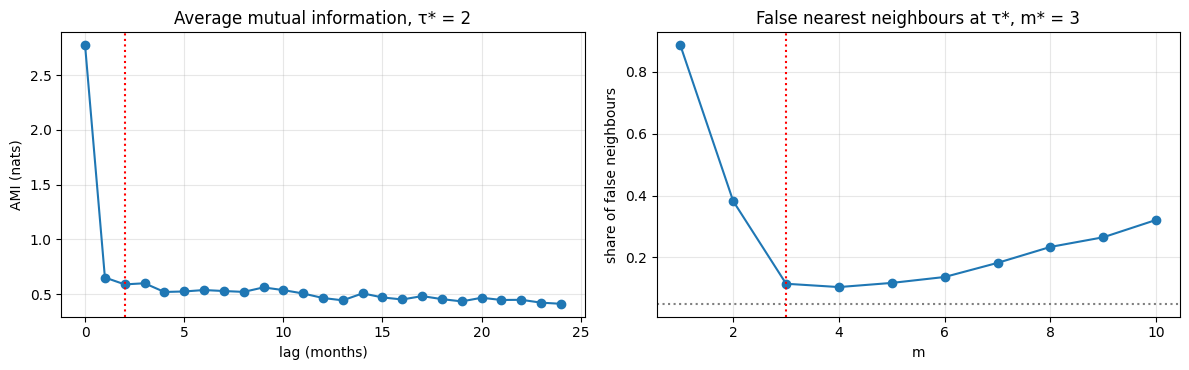

data-chosen embedding: m* = 3, τ* = 2, span (m*-1)τ* = 4 months


In [9]:
# Uses monthly inflation up to 1999 only and never the target
FIT_END = "1999-12-01"
x_fit = macro.PI.loc[:FIT_END].to_numpy()
MAX_LAG, MAX_M, FNN_THEILER = 24, 10, 12

ami = average_mutual_information(x_fit, MAX_LAG)
tau_star = first_local_minimum(ami)
if tau_star is None:  # no minimum: first lag where AMI falls below AMI(0)/e
    tau_star = int(np.flatnonzero(ami < ami[0] / np.e)[0])

fnn = false_nearest_fraction(x_fit, tau_star, MAX_M, theiler=FNN_THEILER)
below = np.flatnonzero(fnn < 0.05)
# Noise keeps FNN above 5%; then take the first m on the plateau (within 0.02 of the smallest FNN)
m_star = int(below[0] + 1) if len(below) else int(np.flatnonzero(fnn <= fnn.min() + 0.02)[0] + 1)
while (m_star - 1) * tau_star > 72:  # keep at least 48 states in a 120-month window
    m_star -= 1
m_star = max(m_star, 2)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(range(MAX_LAG + 1), ami, "o-")
ax[0].axvline(tau_star, color="red", ls=":")
ax[0].set(xlabel="lag (months)", ylabel="AMI (nats)", title=f"Average mutual information, τ* = {tau_star}")
ax[1].plot(range(1, MAX_M + 1), fnn, "o-")
ax[1].axhline(0.05, color="grey", ls=":")
ax[1].axvline(m_star, color="red", ls=":")
ax[1].set(xlabel="m", ylabel="share of false neighbours", title=f"False nearest neighbours at τ*, m* = {m_star}")
for a in ax:
    a.grid(alpha=0.3)
fig.tight_layout()
plt.show()
print(f"data-chosen embedding: m* = {m_star}, τ* = {tau_star}, span (m*-1)τ* = {(m_star - 1) * tau_star} months")

## 6. Window features

Delete `data/processed/embedding_sweep/` after changing feature code.

In [10]:
CACHE_DIR = Path("../../data/processed/embedding_sweep")
SURR_DIR = CACHE_DIR / "iaaft"
SERIES = {"pi": "PI"}
W, RR = 120, 0.05
RQA_KEEP = ["DET", "L", "ENTR", "LAM", "DET3_DET2", "K2_lines", "RR_last"]
RP_COLS = [f"pi_{k}" for k in RQA_KEEP] + ["pi_RRc", "pi_dRRc"]
MOMENT_COLS = ["pi_mean", "pi_std"]
THEILER, RRC_DELTA, N_SURR = 1, 0.05, 19
BETAS = [-5.0, -2.0, -1.0, -0.5, 0.5, 1.0, 2.0, 5.0]
ARMS = ["euclid_z", "euclid_expz", *BETAS]
DATA_CHOSEN = (m_star, tau_star)
EMBEDDINGS = sorted({(2, 1), (3, 6), (3, 12), (4, 3), (6, 3), (8, 3), DATA_CHOSEN}, key=lambda e: ((e[0] - 1) * e[1], e))
ABLATION_EMBEDDING = (2, 1)
assert all(W - (m - 1) * tau >= 48 for m, tau in EMBEDDINGS)


def span(e):
    return (e[0] - 1) * e[1]


def arm_name(arm):
    return arm if isinstance(arm, str) else f"b{arm:g}"


def distance_for(arm):
    if arm == "euclid_z":
        return euclidean_distance
    if arm == "euclid_expz":
        return exp_euclidean_distance
    return partial(beta_distance, beta=arm)


def rp_features(m, tau, arm, data=macro) -> pd.DataFrame:
    df = rqa_frame(data, SERIES, {}, W, m, tau, RR, distance_for(arm), THEILER)
    # ε comes from the target rate, so the RR of the whole window carries no information
    assert df["pi_RR"].std() < 1e-3
    return df


def rrc_features(m, tau, arm, data=macro, surrogates=None) -> pd.DataFrame:
    if surrogates is None:
        surrogates = window_surrogates(data, SERIES, W, N_SURR)
    return rrc_frame(data, SERIES, {}, W, m, tau, distance_for(arm), surrogates, THEILER, RRC_DELTA)


def moments(W, data=macro) -> pd.DataFrame:
    """Mean and std of the raw window; the RP itself only sees the z-scored window."""
    x = data.PI.rolling(W)
    return pd.DataFrame({"pi_mean": x.mean(), "pi_std": x.std(ddof=0)}).iloc[W - 1 :]


def cached(path, build, load=True):
    if path.exists():
        return pd.read_pickle(path) if load else None
    path.parent.mkdir(parents=True, exist_ok=True)
    obj = build()
    tmp = path.with_suffix(".tmp")
    pd.to_pickle(obj, tmp)
    tmp.replace(path)
    return obj if load else None


def load_surrogates(W, load=True):
    return cached(SURR_DIR / f"W{W}_n{N_SURR}.pkl", lambda: window_surrogates(macro, SERIES, W, N_SURR), load)


def arm_paths(m, tau, arm):
    name = f"m{m}_tau{tau}_{arm_name(arm)}.pkl"
    return CACHE_DIR / "rqa" / name, CACHE_DIR / "rrc" / name


def load_rp(m, tau, arm, load=True):
    rqa_path, rrc_path = arm_paths(m, tau, arm)
    rqa_df = cached(rqa_path, lambda: rp_features(m, tau, arm), load)
    rrc_df = cached(rrc_path, lambda: rrc_features(m, tau, arm, surrogates=load_surrogates(W)), load)
    return rqa_df.join(rrc_df)[RP_COLS] if load else None


def build(keys):
    load_surrogates(W, load=False)
    todo = [k for k in keys if not all(p.exists() for p in arm_paths(*k))]
    # Each (m, tau, arm) writes only its own files, so parallel jobs never collide
    Parallel(n_jobs=-1)(delayed(load_rp)(*k, load=False) for k in todo)
    return {k: load_rp(*k) for k in keys}

In [11]:
PROFILE_MEASURES = RP_COLS


def beta_profile(m, tau) -> pd.DataFrame:
    """Per month and measure, a quadratic in x = β/5 over the 8 β: level c0, slope c1, curvature c2."""
    x = np.array(BETAS) / 5
    idx = rp[m, tau, BETAS[0]].index
    cols = {}
    for meas in PROFILE_MEASURES:
        V = np.column_stack([rp[m, tau, b][meas].reindex(idx).to_numpy() for b in BETAS])
        coef = np.full((len(V), 3), np.nan)
        finite = np.isfinite(V)
        for pattern in np.unique(finite, axis=0):
            if pattern.sum() < 3:
                continue
            rows = (finite == pattern).all(axis=1)
            coef[rows] = np.polyfit(x[pattern], V[rows][:, pattern].T, 2).T
        cols[f"{meas}_curv"], cols[f"{meas}_slope"], cols[f"{meas}_level"] = coef.T
    order = [f"{m_}_{k}" for m_ in PROFILE_MEASURES for k in ("level", "slope", "curv")]
    return pd.DataFrame(cols, index=idx)[order]


t0 = time.perf_counter()
rp = build([(m, tau, arm) for m, tau in EMBEDDINGS for arm in ARMS])
profiles = {e: beta_profile(*e) for e in EMBEDDINGS}
window_moments = moments(W)
print(f"{len(rp)} (embedding, arm) feature sets in {time.perf_counter() - t0:.0f} s")

70 (embedding, arm) feature sets in 271 s


## 7. Checks

In [12]:
for m, tau, arm in [(3, 12, "euclid_z"), (8, 3, -0.5)]:
    for month in ["1980-06-01", "1995-01-01", "2020-04-01"]:
        # Only the last window plus one month: the row for `month` must not need anything else
        sub = macro.loc[:month].iloc[-(W + 1):]
        trunc = rp_features(m, tau, arm, sub).join(rrc_features(m, tau, arm, sub))[RP_COLS]
        assert np.allclose(rp[m, tau, arm].loc[month], trunc.loc[month], equal_nan=True), (m, tau, arm, month)

# β = 2 is half the squared Euclidean distance of exp(z) states, so the RPs at a fixed rate are identical
for m, tau in EMBEDDINGS:
    a, b = rp[m, tau, 2.0].to_numpy(), rp[m, tau, "euclid_expz"].to_numpy()
    mismatch = (~np.isclose(a, b, equal_nan=True)).any(axis=1).mean()
    assert mismatch < 0.01, (m, tau, mismatch)
print("leakage check passed; β = 2 matches Euclidean on exp(z) for every embedding")

leakage check passed; β = 2 matches Euclidean on exp(z) for every embedding


## 8. Models and scoring

In [13]:
FOCUS = [6, 12]
PERIODS = {"screen": SCREEN_YEARS, "final": FINAL_YEARS}
REF = "lags+base+mean/std"


def features(model, h):
    """model is a name for the ablation/reference models, or (m, tau, arm) with arm in ARMS or "beta_profile"."""
    base = lag_base_features[h]
    if model == "lags+base":
        return base
    if model == REF:
        return base.join(window_moments)
    if model == "lags+base+RQA/RRc":
        return base.join(rp[(*ABLATION_EMBEDDING, "euclid_z")])
    if model == "lags+base+both":
        return base.join(window_moments).join(rp[(*ABLATION_EMBEDDING, "euclid_z")])
    m, tau, arm = model
    block = profiles[m, tau] if arm == "beta_profile" else rp[m, tau, arm]
    return base.join(window_moments).join(block)


results = {}


def fit_all(models, period, horizons=FOCUS):
    jobs = [(mdl, h) for mdl in models for h in horizons if (period, mdl, h) not in results]
    out = Parallel(n_jobs=-1)(delayed(evaluate)(features(mdl, h), h, *PERIODS[period]) for mdl, h in jobs)
    results.update({(period, mdl, h): r for (mdl, h), r in zip(jobs, out)})


def auc(period, model, h):
    return results[period, model, h][0]["auc"]


def gain(period, model, ref, h):
    return auc_gain(results[period, model, h][1], results[period, ref, h][1], targets[h])


ABLATION = ["lags+base", REF, "lags+base+RQA/RRc", "lags+base+both"]
SWEEP = [(m, tau, arm) for m, tau in EMBEDDINGS for arm in ARMS + ["beta_profile"]]
t0 = time.perf_counter()
for period in PERIODS:
    fit_all(ABLATION + SWEEP, period)
assert all(r[0]["n_test"] == 300 for (p, _, _), r in results.items() if p == "screen")
print(f"{len(results)} models in {time.perf_counter() - t0:.0f} s")

324 models in 71 s


## 9. Ablation: mean/std vs recurrence structure

In [14]:
rows = []
for period in PERIODS:
    for h in FOCUS:
        for model in ABLATION:
            row = {"period": period, "h": h, "model": model, "auc": auc(period, model, h)}
            if model != "lags+base":
                row["gain vs lags+base"], row["lo"], row["hi"] = gain(period, model, "lags+base", h)
            rows.append(row)
        g, lo, hi = gain(period, "lags+base+both", REF, h)
        rows.append({"period": period, "h": h, "model": "both minus mean/std", "gain vs lags+base": g, "lo": lo, "hi": hi})
ablation = pd.DataFrame(rows).set_index(["period", "h", "model"])
ablation.round(4)

auc  gain vs lags+base      lo      hi
period h  model                                                         
screen 6  lags+base            0.6929                NaN     NaN     NaN
          lags+base+mean/std   0.6605            -0.0324 -0.0944  0.0233
          lags+base+RQA/RRc    0.7593             0.0664 -0.0035  0.1408
          lags+base+both       0.7258             0.0328 -0.0416  0.1140
          both minus mean/std     NaN             0.0653 -0.0081  0.1349
       12 lags+base            0.5022                NaN     NaN     NaN
          lags+base+mean/std   0.4376            -0.0646 -0.1892  0.0656
          lags+base+RQA/RRc    0.6487             0.1465 -0.0397  0.3218
          lags+base+both       0.6442             0.1420 -0.0594  0.3332
          both minus mean/std     NaN             0.2066  0.0189  0.3787
final  6  lags+base            0.7533                NaN     NaN     NaN
          lags+base+mean/std   0.7895             0.0362 -0.0188  0.0904
          lags+base+RQA/RRc    0.7928             0.0395 -0.0247  0.1067
          lags+base+both       0.7967             0.0434 -0.0273  0.1174
          both minus mean/std     NaN             0.0072 -0.0258  0.0433
       12 lags+base            0.6676                NaN     NaN     NaN
          lags+base+mean/std   0.7321             0.0646 -0.0229  0.1602
          lags+base+RQA/RRc    0.7526             0.0851  0.0051  0.1720
          lags+base+both       0.7575             0.0900 -0.0104  0.1902
          both minus mean/std     NaN             0.0254 -0.0162  0.0621

## 10. Embedding sweep

In [15]:
def best_beta(e, h):
    """Chosen on screening AUC among the 8 β; ties go to the smaller β."""
    return max(BETAS, key=lambda b: (auc("screen", (*e, b), h), -b))


rows = []
for e in EMBEDDINGS:
    for h in FOCUS:
        arms = {"euclid_z": "euclid_z", "euclid_expz": "euclid_expz", "best β": best_beta(e, h),
                "beta_profile": "beta_profile"}
        for period in PERIODS:
            row = {"m": e[0], "tau": e[1], "span": span(e), "data-chosen": e == DATA_CHOSEN, "h": h,
                   "period": period, "best β": arms["best β"],
                   "lags+base AUC": auc(period, "lags+base", h), f"{REF} AUC": auc(period, REF, h)}
            for name, arm in arms.items():
                row[f"{name} AUC"] = auc(period, (*e, arm), h)
                row[f"{name} gain"], row[f"{name} lo"], row[f"{name} hi"] = gain(period, (*e, arm), REF, h)
            rows.append(row)
sweep = pd.DataFrame(rows)

AUC_COLS = ["best β AUC", "lags+base AUC", "euclid_z AUC", "euclid_expz AUC", "beta_profile AUC", f"{REF} AUC"]
five_arm = sweep.set_index(["period", "h", "m", "tau", "span"])[["best β", *AUC_COLS]].sort_index()
five_arm.round(4)

best β  best β AUC  lags+base AUC  euclid_z AUC  \
period h  m tau span                                                    
final  6  2 1   1       -0.5      0.7801         0.7533        0.7967   
          3 2   4       -2.0      0.7888         0.7533        0.7582   
            6   12      -5.0      0.7758         0.7533        0.7931   
            12  24       1.0      0.7921         0.7533        0.7854   
          4 3   9        5.0      0.7803         0.7533        0.7801   
          6 3   15       5.0      0.7818         0.7533        0.7957   
          8 3   21       5.0      0.7896         0.7533        0.7768   
       12 2 1   1       -0.5      0.7206         0.6676        0.7575   
          3 2   4       -2.0      0.7230         0.6676        0.6950   
            6   12      -2.0      0.7283         0.6676        0.7472   
            12  24       1.0      0.7187         0.6676        0.7220   
          4 3   9       -2.0      0.6986         0.6676        0.7307   
          6 3   15       5.0      0.7137         0.6676        0.7654   
          8 3   21       2.0      0.7385         0.6676        0.7079   
screen 6  2 1   1       -0.5      0.7327         0.6929        0.7258   
          3 2   4       -2.0      0.7786         0.6929        0.5999   
            6   12      -5.0      0.6827         0.6929        0.6457   
            12  24       1.0      0.6704         0.6929        0.6345   
          4 3   9        5.0      0.6771         0.6929        0.6170   
          6 3   15       5.0      0.6625         0.6929        0.5885   
          8 3   21       5.0      0.6812         0.6929        0.6649   
       12 2 1   1       -0.5      0.6415         0.5022        0.6442   
          3 2   4       -2.0      0.5654         0.5022        0.4569   
            6   12      -2.0      0.4633         0.5022        0.3918   
            12  24       1.0      0.5417         0.5022        0.4407   
          4 3   9       -2.0      0.5094         0.5022        0.4380   
          6 3   15       5.0      0.5231         0.5022        0.3497   
          8 3   21       2.0      0.5796         0.5022        0.4482   

                      euclid_expz AUC  beta_profile AUC  \
period h  m tau span                                      
final  6  2 1   1              0.7857            0.7750   
          3 2   4              0.7788            0.7515   
            6   12             0.7761            0.7827   
            12  24             0.7904            0.7681   
          4 3   9              0.7980            0.7677   
          6 3   15             0.7737            0.7753   
          8 3   21             0.7781            0.7773   
       12 2 1   1              0.7547            0.7292   
          3 2   4              0.7285            0.6673   
            6   12             0.7483            0.7305   
            12  24             0.7095            0.7068   
          4 3   9              0.7140            0.6777   
          6 3   15             0.7244            0.7269   
          8 3   21             0.7385            0.7209   
screen 6  2 1   1              0.6784            0.7071   
          3 2   4              0.5903            0.6483   
            6   12             0.6390            0.5780   
            12  24             0.6227            0.5836   
          4 3   9              0.6169            0.5989   
          6 3   15             0.6472            0.6063   
          8 3   21             0.6592            0.6261   
       12 2 1   1              0.5306            0.5240   
          3 2   4              0.3992            0.4665   
            6   12             0.3998            0.4185   
            12  24             0.4601            0.4647   
          4 3   9              0.3670            0.4025   
          6 3   15             0.4966            0.4343   
          8 3   21             0.5796            0.4885   

                      lags+base+mean/std AUC  
period h  m t

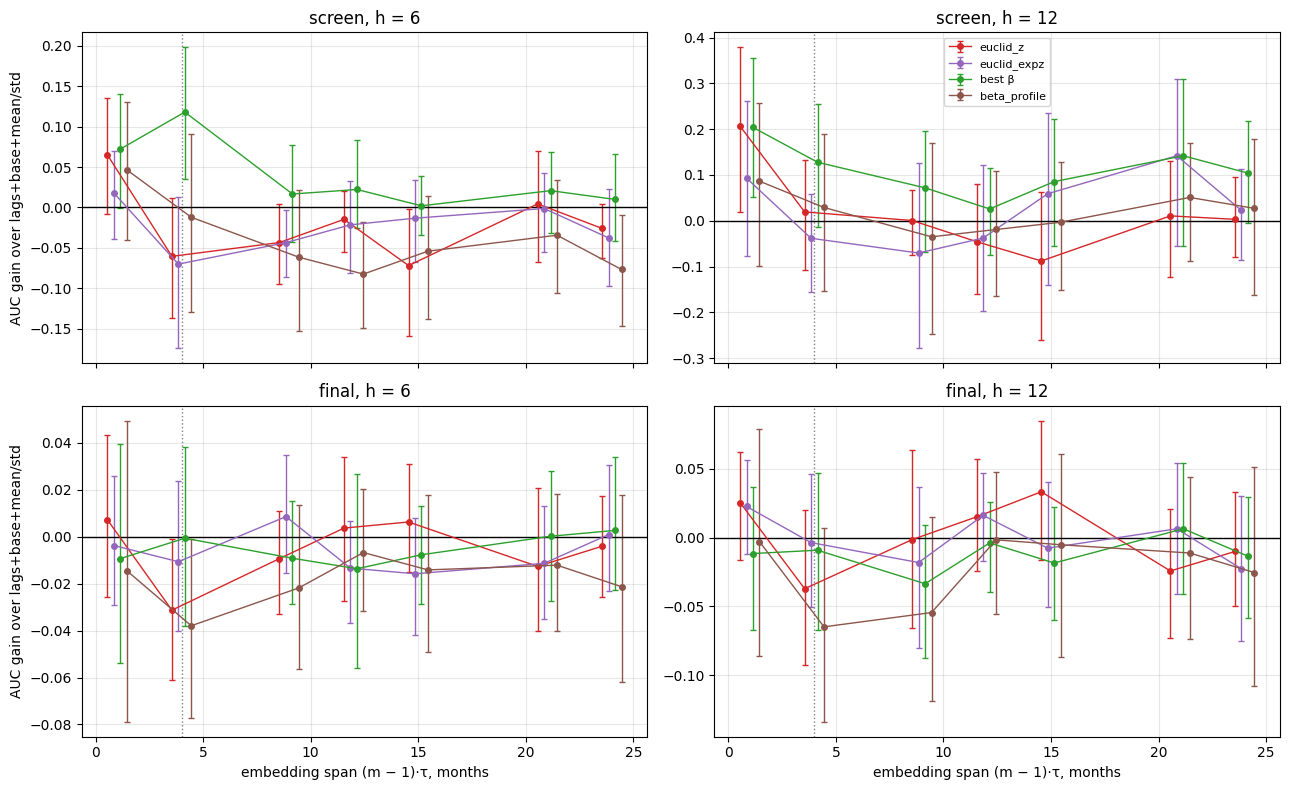

Data-chosen embedding m = 3, τ = 2, final gain of euclid_z over lags+base+mean/std:
    euclid_z AUC  lags+base+mean/std AUC  euclid_z gain  euclid_z lo  \
h                                                                      
6         0.7582                  0.7895        -0.0313      -0.0609   
12        0.6950                  0.7321        -0.0371      -0.0928   

    euclid_z hi  
h                
6       -0.0010  
12       0.0199  


In [16]:
ARM_STYLE = {"euclid_z": "tab:red", "euclid_expz": "tab:purple", "best β": "tab:green", "beta_profile": "tab:brown"}
fig, axes = plt.subplots(2, len(FOCUS), figsize=(13, 8), sharex=True)
for row, period in enumerate(PERIODS):
    for col, h in enumerate(FOCUS):
        ax = axes[row, col]
        d = sweep[(sweep.period == period) & (sweep.h == h)].sort_values("span")
        for k, (name, color) in enumerate(ARM_STYLE.items()):
            x = d.span + (k - 1.5) * 0.3
            ax.errorbar(x, d[f"{name} gain"], yerr=[d[f"{name} gain"] - d[f"{name} lo"], d[f"{name} hi"] - d[f"{name} gain"]],
                        fmt="o-", color=color, ms=4, lw=1, capsize=2, label=name)
        chosen = d[d["data-chosen"]]
        ax.axvline(chosen.span.iloc[0], color="grey", ls=":", lw=1)
        ax.axhline(0, color="black", lw=1)
        ax.set_title(f"{period}, h = {h}")
        ax.grid(alpha=0.3)
        if row == 1:
            ax.set_xlabel("embedding span (m − 1)·τ, months")
    axes[row, 0].set_ylabel(f"AUC gain over {REF}")
axes[0, -1].legend(fontsize=8)
fig.tight_layout()
plt.show()

primary = sweep[sweep["data-chosen"] & (sweep.period == "final")].set_index("h")
print(f"Data-chosen embedding m = {m_star}, τ = {tau_star}, final gain of euclid_z over {REF}:")
print(primary[["euclid_z AUC", f"{REF} AUC", "euclid_z gain", "euclid_z lo", "euclid_z hi"]].round(4))